# Exploración, limpieza e integración preliminar de datos

Proyecto: Predicción de denuncias policiales por distrito en el Perú mediante aprendizaje automático y variables sociodemográficas.

Este notebook realiza una exploración inicial de las fuentes, verifica su calidad y genera un dataset preliminar a nivel distrito-mes.

In [36]:
from google.colab import files

print("Selecciona los tres archivos:")
print("1. Denuncias Policiales.csv")
print("2. Indice de pbreza.xlsx")
print("3. Densidad de población.xlsx")

archivos_subidos = files.upload()

Selecciona los tres archivos:
1. Denuncias Policiales.csv
2. Indice de pbreza.xlsx
3. Densidad de población.xlsx


In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# Ubicar automáticamente los archivos subidos
archivos_csv = list(Path("/content").glob("*.csv"))
archivos_excel = list(Path("/content").glob("*.xlsx"))

DENUNCIAS_PATH = archivos_csv[0]

POBREZA_PATH = next(
    archivo for archivo in archivos_excel
    if "pbreza" in archivo.name.lower() or "pobreza" in archivo.name.lower()
)

POBLACION_PATH = next(
    archivo for archivo in archivos_excel
    if archivo != POBREZA_PATH
)

print("Archivo de denuncias:", DENUNCIAS_PATH.name)
print("Archivo de pobreza:", POBREZA_PATH.name)
print("Archivo de población:", POBLACION_PATH.name)

# Lectura segura del CSV
def leer_csv_seguro(ruta):
    for codificacion in ["utf-8-sig", "latin-1"]:
        try:
            return pd.read_csv(ruta, encoding=codificacion)
        except UnicodeDecodeError:
            continue
    raise ValueError("No fue posible leer el archivo CSV.")

denuncias = leer_csv_seguro(DENUNCIAS_PATH)

# Los Excel se leen sin encabezado inicialmente porque tienen títulos y notas arriba
pobreza_bruta = pd.read_excel(POBREZA_PATH, sheet_name="Anexo1", header=None)
poblacion_bruta = pd.read_excel(POBLACION_PATH, sheet_name=0, header=None)

Archivo de denuncias: Denuncias Policiales.csv
Archivo de pobreza: Indice de pbreza.xlsx
Archivo de población: Densidad de  población (1).xlsx


/usr/local/lib/python3.13/dist-packages/openpyxl/reader/workbook.py:118: UserWarning: Print area cannot be set to Defined name: 'A3.23'!$A:$I.
  warn(f"Print area cannot be set to Defined name: {defn.value}.")


In [38]:
print("DIMENSIONES DE LOS DATASETS")
print("Denuncias:", denuncias.shape)
print("Pobreza:", pobreza_bruta.shape)
print("Población:", poblacion_bruta.shape)

print("\nCOLUMNAS DEL DATASET DE DENUNCIAS")
display(denuncias.head())

print("\nPRIMERAS FILAS DEL DATASET DE POBREZA")
display(pobreza_bruta.head(10))

print("\nPRIMERAS FILAS DEL DATASET DE POBLACIÓN")
display(poblacion_bruta.head(10))

print("\nVALORES NULOS EN DENUNCIAS")
display(denuncias.isnull().sum().sort_values(ascending=False))

DIMENSIONES DE LOS DATASETS
Denuncias: (369100, 8)
Pobreza: (1922, 9)
Población: (2145, 11)

COLUMNAS DEL DATASET DE DENUNCIAS


,ANIO,MES,DPTO_HECHO_NEW,PROV_HECHO,DIST_HECHO,UBIGEO_HECHO,P_MODALIDADES,cantidad
0,2018,1,AMAZONAS,BAGUA,ARAMANGO,10202,Otros,4
1,2018,1,AMAZONAS,BAGUA,ARAMANGO,10202,Violencia contra la mujer e integrantes,3
2,2018,1,AMAZONAS,BAGUA,BAGUA,10201,Estafa,2
3,2018,1,AMAZONAS,BAGUA,BAGUA,10201,Hurto,25
4,2018,1,AMAZONAS,BAGUA,BAGUA,10201,Otros,52



PRIMERAS FILAS DEL DATASET DE POBREZA


,0,1,2,3,4,5,6,7,8
0,Anexo N° 1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"PERÚ: POBREZA MONETARIA TOTAL, GRUPOS ROBUSTOS...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Ubigeo,Departamento,Provincia,Distrito,Población proyectada\n2020\n1/,Intervalo de confianza al 95%,NaN,Grupos robustos 2/,Ubicación pobreza monetaria total \n3/
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,Inferior,Superior,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,050410,AYACUCHO,HUANTA,UCHURACCAY,3672,73.254961,89.268381,1,1
8,060308,CAJAMARCA,CELENDÍN,OXAMARCA,5824,74.592076,87.404338,1,2
9,060402,CAJAMARCA,CHOTA,ANGUIA,3216,71.738599,85.685853,1,3



PRIMERAS FILAS DEL DATASET DE POBLACIÓN


,0,1,2,3,4,5,6,7,8,9,10
0,CUADRO Nº 01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,PERÚ: POBLACIÓN TOTAL PROYECTADA AL 30 DE JUNI...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,(Información de carácter referencial),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,UBIGEO,"Departamento, provincia y distrito",Población proyectada 1/,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,2018,2019,2020,2021,2022,2023,2024,2025.0,2026.0
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,000000,PERÚ,31562130,32131400,32625948,33035304,33396698,33725844,34038457,34350244.0,34660114.0
7,010000,AMAZONAS,419833,423863,426806,428512,429483,429943,430123,430251.0,430305.0
8,010100,CHACHAPOYAS,61078,62207,63188,63661,64058,64403,64718,65024.0,65320.0
9,010101,CHACHAPOYAS,36602,37870,39051,39691,40274,40817,41335,41843.0,42342.0



VALORES NULOS EN DENUNCIAS


,0
ANIO,0
MES,0
DPTO_HECHO_NEW,0
PROV_HECHO,0
DIST_HECHO,0
UBIGEO_HECHO,0
P_MODALIDADES,0
cantidad,0


In [39]:
def normalizar_ubigeo(serie):
    """
    Convierte los ubigeos a texto de seis dígitos.
    Ejemplo: 10202 se transforma en 010202.
    """
    numeros = pd.to_numeric(serie, errors="coerce")
    return numeros.astype("Int64").astype("string").str.zfill(6)

In [40]:
denuncias.columns = denuncias.columns.str.strip().str.upper()

denuncias["UBIGEO"] = normalizar_ubigeo(denuncias["UBIGEO_HECHO"])
denuncias["ANIO"] = pd.to_numeric(denuncias["ANIO"], errors="coerce").astype("Int64")
denuncias["MES"] = pd.to_numeric(denuncias["MES"], errors="coerce").astype("Int64")
denuncias["CANTIDAD"] = pd.to_numeric(denuncias["CANTIDAD"], errors="coerce")

# Eliminar filas sin información indispensable
denuncias_limpias = denuncias.dropna(
    subset=["UBIGEO", "ANIO", "MES", "CANTIDAD"]
).copy()

# Mantener solo ubigeos distritales.
# Los códigos que terminan en 00 corresponden a agregaciones de provincia/departamento.
denuncias_limpias = denuncias_limpias[
    (denuncias_limpias["MES"].between(1, 12)) &
    (denuncias_limpias["UBIGEO"].str[-2:] != "00")
].copy()

denuncias_limpias["FECHA"] = pd.to_datetime(
    dict(
        year=denuncias_limpias["ANIO"].astype(int),
        month=denuncias_limpias["MES"].astype(int),
        day=1
    )
)

# Una fila final por distrito y mes
denuncias_mes = (
    denuncias_limpias
    .groupby(["UBIGEO", "ANIO", "MES", "FECHA"], as_index=False)
    .agg(
        DENUNCIAS_TOTALES=("CANTIDAD", "sum"),
        MODALIDADES_REGISTRADAS=("P_MODALIDADES", "nunique")
    )
)

print("Registros originales de denuncias:", len(denuncias))
print("Registros luego de limpieza:", len(denuncias_limpias))
print("Registros consolidados distrito-mes:", len(denuncias_mes))

display(denuncias_mes.head())

Registros originales de denuncias: 369100
Registros luego de limpieza: 369100
Registros consolidados distrito-mes: 124794


,UBIGEO,ANIO,MES,FECHA,DENUNCIAS_TOTALES,MODALIDADES_REGISTRADAS
0,010101,2018,1,2018-01-01,152,6
1,010101,2018,2,2018-02-01,153,6
2,010101,2018,3,2018-03-01,150,7
3,010101,2018,4,2018-04-01,139,5
4,010101,2018,5,2018-05-01,130,5


In [41]:
# Los datos reales empiezan desde la fila 7 del Excel
poblacion = poblacion_bruta.iloc[6:, :11].copy()

poblacion.columns = [
    "UBIGEO",
    "NOMBRE_TERRITORIO",
    2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026
]

poblacion["UBIGEO"] = normalizar_ubigeo(poblacion["UBIGEO"])

poblacion = poblacion.dropna(subset=["UBIGEO"]).copy()

# Se excluyen Perú, departamentos y provincias para conservar distritos
poblacion = poblacion[
    poblacion["UBIGEO"].str[-2:] != "00"
].copy()

# Convertir la tabla de años en columnas a una tabla larga: distrito-año
poblacion_larga = poblacion.melt(
    id_vars=["UBIGEO", "NOMBRE_TERRITORIO"],
    value_vars=list(range(2018, 2027)),
    var_name="ANIO",
    value_name="POBLACION_PROYECTADA"
)

poblacion_larga["ANIO"] = poblacion_larga["ANIO"].astype("Int64")
poblacion_larga["POBLACION_PROYECTADA"] = pd.to_numeric(
    poblacion_larga["POBLACION_PROYECTADA"],
    errors="coerce"
)

poblacion_larga = poblacion_larga.dropna(
    subset=["POBLACION_PROYECTADA"]
).copy()

poblacion_larga = poblacion_larga.sort_values(["UBIGEO", "ANIO"])

# Crecimiento porcentual respecto al año anterior
poblacion_larga["CRECIMIENTO_POBLACIONAL_PCT"] = (
    poblacion_larga
    .groupby("UBIGEO")["POBLACION_PROYECTADA"]
    .pct_change() * 100
)

print("Registros distrito-año de población:", len(poblacion_larga))
display(poblacion_larga.head())

Registros distrito-año de población: 16969


,UBIGEO,NOMBRE_TERRITORIO,ANIO,POBLACION_PROYECTADA,CRECIMIENTO_POBLACIONAL_PCT
0,010101,CHACHAPOYAS,2018,36602.0,NaN
1892,010101,CHACHAPOYAS,2019,37870.0,3.464292
3784,010101,CHACHAPOYAS,2020,39051.0,3.118564
5676,010101,CHACHAPOYAS,2021,39691.0,1.638882
7568,010101,CHACHAPOYAS,2022,40274.0,1.468847


In [42]:
# En el Anexo 1, los datos empiezan desde la fila 8
pobreza = pobreza_bruta.iloc[7:, :9].copy()

pobreza.columns = [
    "UBIGEO",
    "DEPARTAMENTO",
    "PROVINCIA",
    "DISTRITO",
    "POBLACION_2020_REFERENCIAL",
    "POBREZA_INF",
    "POBREZA_SUP",
    "GRUPO_ROBUSTO",
    "UBICACION_POBREZA"
]

pobreza["UBIGEO"] = normalizar_ubigeo(pobreza["UBIGEO"])

for columna in ["POBREZA_INF", "POBREZA_SUP"]:
    pobreza[columna] = pd.to_numeric(pobreza[columna], errors="coerce")

pobreza = pobreza.dropna(
    subset=["UBIGEO", "POBREZA_INF", "POBREZA_SUP"]
).copy()

pobreza = pobreza[
    pobreza["UBIGEO"].str[-2:] != "00"
].copy()

# Punto medio del intervalo de pobreza monetaria
pobreza["POBREZA_PUNTO_MEDIO_PCT"] = (
    pobreza["POBREZA_INF"] + pobreza["POBREZA_SUP"]
) / 2

pobreza = pobreza[
    [
        "UBIGEO",
        "POBREZA_INF",
        "POBREZA_SUP",
        "POBREZA_PUNTO_MEDIO_PCT",
        "GRUPO_ROBUSTO",
        "UBICACION_POBREZA"
    ]
].drop_duplicates(subset="UBIGEO")

print("Distritos con información de pobreza:", len(pobreza))
display(pobreza.head())

Distritos con información de pobreza: 1873


,UBIGEO,POBREZA_INF,POBREZA_SUP,POBREZA_PUNTO_MEDIO_PCT,GRUPO_ROBUSTO,UBICACION_POBREZA
7,050410,73.254961,89.268381,81.261671,1,1
8,060308,74.592076,87.404338,80.998207,1,2
9,060402,71.738599,85.685853,78.712226,1,3
10,050411,65.844650,90.477852,78.161251,2,4
11,090722,65.638998,88.611786,77.125392,2,5


In [43]:
dataset_preliminar = (
    denuncias_mes
    .merge(
        poblacion_larga[
            [
                "UBIGEO",
                "ANIO",
                "POBLACION_PROYECTADA",
                "CRECIMIENTO_POBLACIONAL_PCT"
            ]
        ],
        on=["UBIGEO", "ANIO"],
        how="left"
    )
    .merge(
        pobreza,
        on="UBIGEO",
        how="left"
    )
)

# Tasa mensual por cada 100 000 habitantes
dataset_preliminar["TASA_DENUNCIAS_100K"] = (
    dataset_preliminar["DENUNCIAS_TOTALES"] /
    dataset_preliminar["POBLACION_PROYECTADA"]
) * 100000

dataset_preliminar = dataset_preliminar.sort_values(
    ["UBIGEO", "FECHA"]
).reset_index(drop=True)

print("Dimensiones del dataset integrado:", dataset_preliminar.shape)
display(dataset_preliminar.head())

Dimensiones del dataset integrado: (124794, 14)


,UBIGEO,ANIO,MES,FECHA,DENUNCIAS_TOTALES,MODALIDADES_REGISTRADAS,POBLACION_PROYECTADA,CRECIMIENTO_POBLACIONAL_PCT,POBREZA_INF,POBREZA_SUP,POBREZA_PUNTO_MEDIO_PCT,GRUPO_ROBUSTO,UBICACION_POBREZA,TASA_DENUNCIAS_100K
0,010101,2018,1,2018-01-01,152,6,36602.0,NaN,5.773728,12.295522,9.034625,19,1747,415.277854
1,010101,2018,2,2018-02-01,153,6,36602.0,NaN,5.773728,12.295522,9.034625,19,1747,418.009945
2,010101,2018,3,2018-03-01,150,7,36602.0,NaN,5.773728,12.295522,9.034625,19,1747,409.813671
3,010101,2018,4,2018-04-01,139,5,36602.0,NaN,5.773728,12.295522,9.034625,19,1747,379.760669
4,010101,2018,5,2018-05-01,130,5,36602.0,NaN,5.773728,12.295522,9.034625,19,1747,355.171849


In [44]:
print("VALORES NULOS DEL DATASET INTEGRADO")
display(
    dataset_preliminar.isnull()
    .sum()
    .sort_values(ascending=False)
    .to_frame("cantidad_nulos")
)

print("\nCOBERTURA TEMPORAL")
display(
    dataset_preliminar.groupby("ANIO")
    .agg(
        registros=("UBIGEO", "size"),
        distritos=("UBIGEO", "nunique"),
        denuncias_totales=("DENUNCIAS_TOTALES", "sum")
    )
)

print("\nCANTIDAD DE DISTRITOS")
print(dataset_preliminar["UBIGEO"].nunique())

print("\nDUPLICADOS DISTRITO-MES")
print(
    dataset_preliminar.duplicated(
        subset=["UBIGEO", "ANIO", "MES"]
    ).sum()
)

VALORES NULOS DEL DATASET INTEGRADO


,cantidad_nulos
CRECIMIENTO_POBLACIONAL_PCT,11410
GRUPO_ROBUSTO,161
POBREZA_PUNTO_MEDIO_PCT,161
POBREZA_SUP,161
POBREZA_INF,161
UBICACION_POBREZA,161
POBLACION_PROYECTADA,4
TASA_DENUNCIAS_100K,4
MODALIDADES_REGISTRADAS,0
DENUNCIAS_TOTALES,0



COBERTURA TEMPORAL


,registros,distritos,denuncias_totales
ANIO,,,
2018,11403,1518,774804
2019,13212,1625,854898
2020,14104,1693,649169
2021,15366,1749,754638
2022,15614,1753,877736
2023,15553,1760,1044843
2024,15582,1760,1014315
2025,15296,1758,895260
2026,8664,1660,494268



CANTIDAD DE DISTRITOS
1839

DUPLICADOS DISTRITO-MES
0


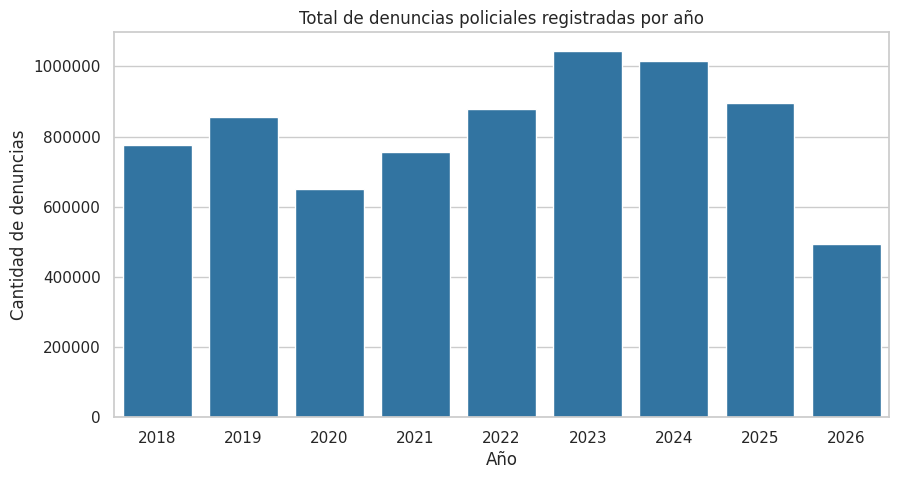

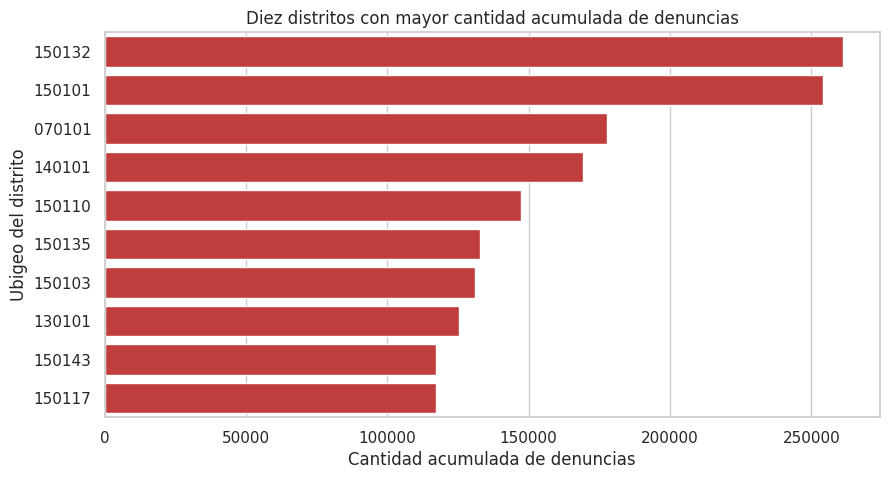

In [45]:
# Denuncias totales por año
denuncias_anuales = (
    dataset_preliminar.groupby("ANIO", as_index=False)
    ["DENUNCIAS_TOTALES"]
    .sum()
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=denuncias_anuales,
    x="ANIO",
    y="DENUNCIAS_TOTALES",
    color="#1f77b4"
)
plt.title("Total de denuncias policiales registradas por año")
plt.xlabel("Año")
plt.ylabel("Cantidad de denuncias")
plt.ticklabel_format(style="plain", axis="y")
plt.show()

# Diez distritos con más denuncias acumuladas
top_distritos = (
    dataset_preliminar.groupby("UBIGEO", as_index=False)
    ["DENUNCIAS_TOTALES"]
    .sum()
    .nlargest(10, "DENUNCIAS_TOTALES")
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=top_distritos,
    x="DENUNCIAS_TOTALES",
    y="UBIGEO",
    color="#d62728"
)
plt.title("Diez distritos con mayor cantidad acumulada de denuncias")
plt.xlabel("Cantidad acumulada de denuncias")
plt.ylabel("Ubigeo del distrito")
plt.ticklabel_format(style="plain", axis="x")
plt.show()

In [46]:
nombre_salida = "dataset_distrito_mes_preliminar.csv"

dataset_preliminar.to_csv(
    nombre_salida,
    index=False,
    encoding="utf-8-sig"
)

print(f"Archivo generado correctamente: {nombre_salida}")
print("Este archivo se usará después para crear rezagos, entrenar y evaluar modelos.")

Archivo generado correctamente: dataset_distrito_mes_preliminar.csv
Este archivo se usará después para crear rezagos, entrenar y evaluar modelos.


## Conclusiones preliminares

- Las tres fuentes pueden relacionarse mediante el código ubigeo distrital.
- Las denuncias se consolidaron a una unidad de análisis distrito-mes.
- La población proyectada permitió calcular la tasa mensual de denuncias por cada 100 000 habitantes.
- El índice de pobreza de 2018 se incorpora como una variable socioeconómica estructural del distrito.
- El dataset preliminar será utilizado posteriormente para crear variables históricas, como rezagos y promedios móviles, antes de entrenar los modelos Random Forest, Gradient Boosting y KNN.
- Los resultados representan denuncias policiales registradas y no la totalidad de delitos ocurridos.